# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [55]:

# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Cargar los tres datasets
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

# Mostrar las primeras 5 filas de cada dataset
print("PLANES")
display(plans.head())

print("USUARIOS")
display(users.head())

print("USO DE SERVICIOS")
display(usage.head())


PLANES


,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


USUARIOS


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


USO DE SERVICIOS


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [56]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [57]:

# Mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [58]:
# Mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [59]:
# Mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [60]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [61]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [62]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [63]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [64]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isna().sum())

print("\nProporción de valores nulos")
print(users.isna().mean())

Cantidad de valores nulos
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [65]:
# cantidad de nulos para usage
print("Cantidad de valores nulos")
print(usage.isna().sum())

print("\nProporción de valores nulos")
print(usage.isna().mean())

Cantidad de valores nulos
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?                                                   ### Diagnóstico de valores nulos

**Dataset `users`:**

- **`city` (11.73 %):** Investigar los registros faltantes y considerar asignar la categoría `"Unknown"` para conservar a los clientes sin inventar su ciudad.
- **`churn_date` (88.35 %):** Conservar los valores nulos, ya que pueden representar clientes que todavía no han cancelado el servicio. Se debe verificar esta interpretación antes de analizar el churn.

**Dataset `usage`:**

- **`date` (0.13 %):** Revisar los 50 registros sin fecha. Si no es posible recuperarla, considerar excluirlos de los análisis temporales.
- **`duration` (55.19 %):** Investigar si los nulos corresponden a registros de mensajes, donde la duración no aplica.
- **`length` (44.74 %):** Investigar si los nulos corresponden a llamadas, donde la longitud del mensaje no aplica.

**Conclusión:**

No todos los valores nulos representan errores. Algunos pueden tener una explicación relacionada con el tipo de registro. Antes de imputar o eliminar datos, es necesario comprender su significado para evitar alterar los resultados del análisis.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [66]:
# explorar columnas numéricas de users
print(users[['user_id', 'age']].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


# explorar columnas numéricas de usage
print(usage[['id', 'user_id', 'duration', 'length']].describe()).

In [67]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"\nValores únicos de {col}:")
    print(users[col].unique())


Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [68]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


- La columna `city` ...
- La columna `plan` ...

In [69]:
# explorar columna categórica de usage
usage['type'].unique()

array(['call', 'text'], dtype=object)

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [70]:
# Convertir a fecha la columna reg_date de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [71]:
# Convertir a fecha la columna date de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [72]:
# Revisar los años presentes en reg_date de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves. En la columna `reg_date` se encontraron registros de 2022, 2023 y 2024, además de 40 registros correspondientes a 2026. Estos últimos están fuera del período de análisis, que termina en 2024. Recomiendo marcarlos como fechas inválidas y revisar su origen antes de decidir cómo tratarlos. No deben corregirse a otro año sin evidencia.

In [73]:
# Revisar los años presentes en date de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.  En la columna `date` de `usage`, los 39.950 registros con fecha válida corresponden al año 2024. No se encontraron años fuera del período de análisis. Sin embargo, existen 50 registros con fechas ausentes, que deben revisarse porque no permiten identificar cuándo ocurrió la actividad.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?                                                                           **Fechas fuera de rango**

En `users['reg_date']` se encontraron 40 registros correspondientes al año 2026. Estas fechas están fuera del período de análisis, ya que los datos del proyecto llegan hasta 2024.

Recomiendo convertir esas 40 fechas en valores nulos (`NaT`), sin inventar una fecha de reemplazo.

En `usage['date']`, los 39.950 registros con fechas válidas corresponden a 2024, por lo que no hay años fuera de rango. Sin embargo, existen 50 fechas ausentes que deben revisarse antes de realizar análisis temporales.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [74]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()

users['age'] = users['age'].replace(-999, age_mediana)

print(users['age'].describe())

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [75]:
# Reemplazar el sentinel "?" por valores nulos
users['city'] = users['city'].replace('?', pd.NA)

print(users['city'].isna().sum())


565


In [76]:
# Marcar como nulas las fechas posteriores a 2024
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

print(users['reg_date'].isna().sum())


40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [77]:
# Verificación MAR en usage para duration
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [78]:
# Verificación MAR en usage (Missing At Random) para length


**Diagnóstico de valores nulos**

En `duration`, el 99,93 % de los mensajes (`text`) presenta valores nulos, mientras que las llamadas (`call`) no tienen valores ausentes.

En `length`, el 99,93 % de las llamadas presenta valores nulos, mientras que los mensajes no tienen valores ausentes.

Los valores nulos dependen del tipo de actividad (`type`). Recomiendo conservarlos, porque generalmente corresponden a campos que no aplican al tipo de registro. Los pocos casos excepcionales deben revisarse.

In [79]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isna().sum())

print("\nProporción de valores nulos")
print(users.isna().mean())

Cantidad de valores nulos
user_id          0
first_name       0
last_name        0
age              0
city           565
reg_date        40
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.14125
reg_date      0.01000
plan          0.00000
churn_date    0.88350
dtype: float64


In [80]:
**Diagnóstico de valores nulos en `duration` y `length`**

En la columna `duration`, el 0 % de las llamadas (`call`) tiene valores nulos, mientras que el 99,93 % de los mensajes (`text`) presenta valores ausentes.

En la columna `length`, el 99,93 % de las llamadas tiene valores nulos, mientras que el 0 % de los mensajes presenta valores ausentes.

Estos resultados indican que los valores nulos dependen del tipo de actividad (`type`), ya que `duration` corresponde a llamadas y `length` corresponde a mensajes.

**Decisión:** conservar los valores nulos, porque en su mayoría son esperados según el tipo de actividad. No se recomienda reemplazarlos por cero ni eliminar esos registros.

También se deben revisar los pocos casos excepcionales en los que aparecen valores en columnas que normalmente no corresponden al tipo de actividad.

SyntaxError: invalid syntax (128389653.py, line 1)

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage['is_text'] = (usage['type'] == 'text').astype(int)
usage['is_call'] = (usage['type'] == 'call').astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# Observar resultado
usage_agg.head(3)

In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# Observar resultado
usage_agg.head(3)

In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Mostrar las primeras 5 filas
user_profile.head(5)

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:

# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

print(user_profile[columnas_numericas].describe())


In [ ]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [ ]:
user_profile['age'] = user_profile['age'].replace(-999, float('nan'))
user_profile['age'] = user_profile['age'].fillna(user_profile['age'].median())

print(user_profile['age'].describe())

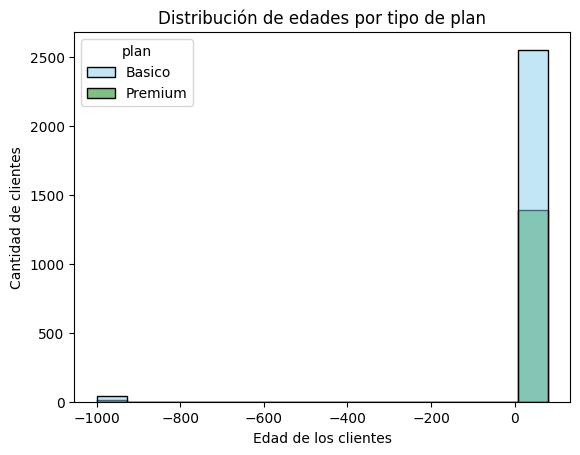

In [88]:
# Histograma para visualizar la edad (age)
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green']
)

plt.title('Distribución de edades por tipo de plan')
plt.xlabel('Edad de los clientes')
plt.ylabel('Cantidad de clientes')
plt.show()

💡Insights: 
La distribución de edades es aproximadamente uniforme entre los 18 y 79 años, sin un sesgo evidente hacia edades jóvenes o mayores. El plan Básico presenta una mayor cantidad de clientes en casi todos los rangos de edad, aunque esto puede explicarse porque tiene más usuarios en total. No se observa una diferencia marcada en la forma de la distribución entre ambos planes.

In [87]:
print(user_profile.columns.tolist())

['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan', 'churn_date', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada', 'grupo_uso', 'grupo_edad']


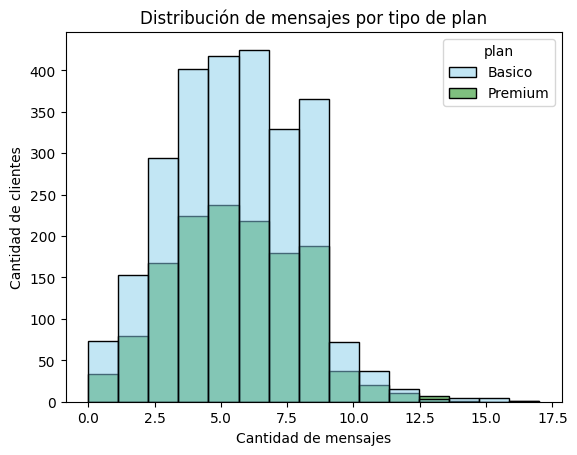

In [86]:
# Histograma para visualizar la cantidad de mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green']
)

plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de clientes')
plt.show()


💡Insights: 
- **Insight — Cantidad de mensajes**

La m
ayoría de los usuarios envía entre 3 y 9 mensajes, con una mayor concentración alrededor de 5 a 7 mensajes. La distribución presenta un ligero sesgo hacia la derecha, porque hay pocos usuarios que envían cantidades más altas, hasta aproximadamente 17 mensajes.

Ambos planes muestran un comportamiento similar. El plan Básico tiene más usuarios en términos absolutos, pero esto no significa necesariamente que sus clientes envíen más mensajes individualmente.

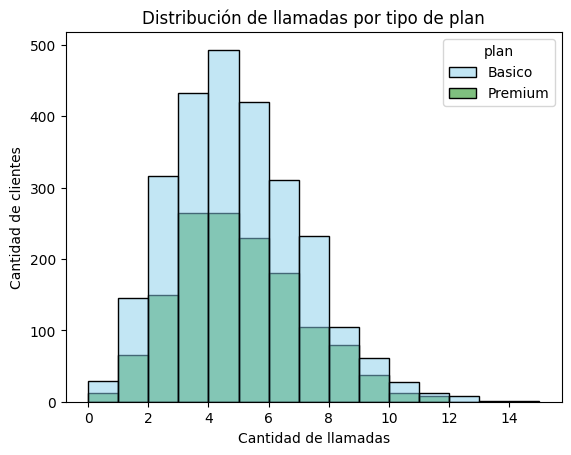

In [85]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green']
)

plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de clientes')
plt.show()


💡Insights: 
- La cantidad de llamadas presenta una distribución ligeramente sesgada a la derecha. La mayoría de los usuarios realiza entre 3 y 7 llamadas. Ambos planes muestran un comportamiento similar, aunque el plan Básico tiene una mayor cantidad de usuarios en casi todos los intervalos.

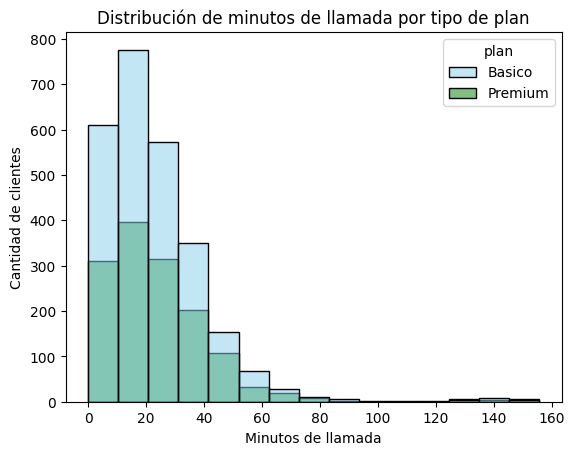

In [84]:
# Histograma de minutos de llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green']
)

plt.title('Distribución de minutos de llamada por tipo de plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de clientes')
plt.show()

💡Insights: 
- La distribución de minutos de llamada está sesgada a la derecha. La mayoría de los usuarios acumula entre 0 y 40 minutos, mientras que unos pocos registran valores mucho más altos. Ambos planes presentan patrones similares, aunque el plan Básico tiene más clientes en la mayoría de los intervalos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

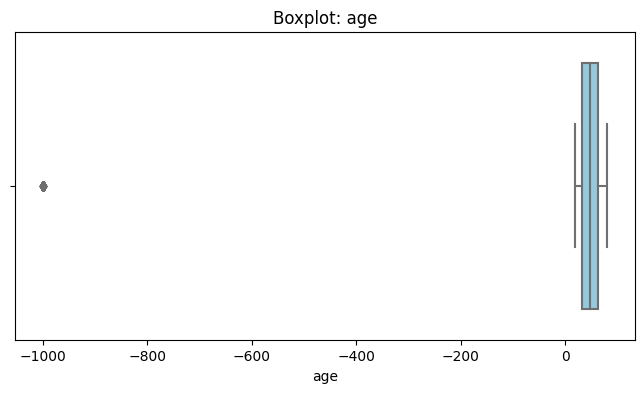

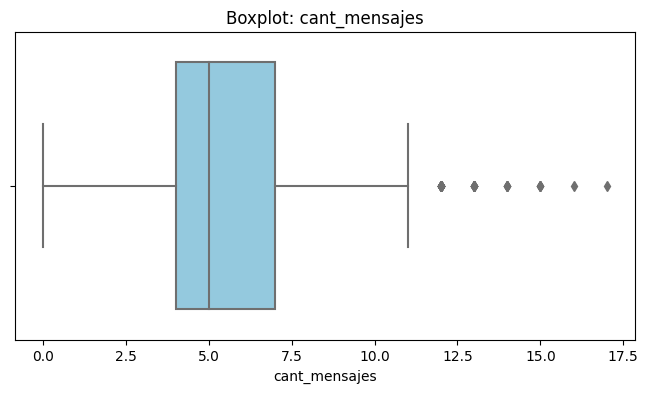

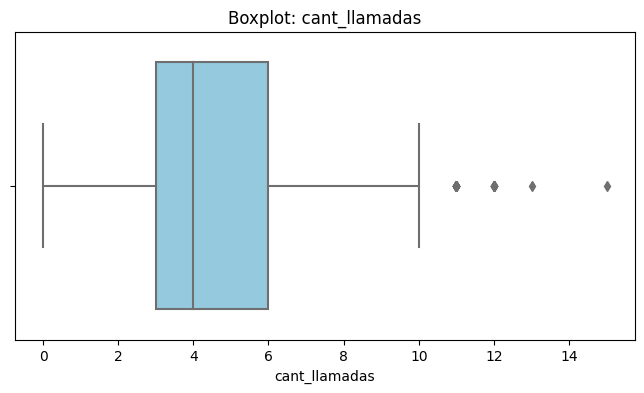

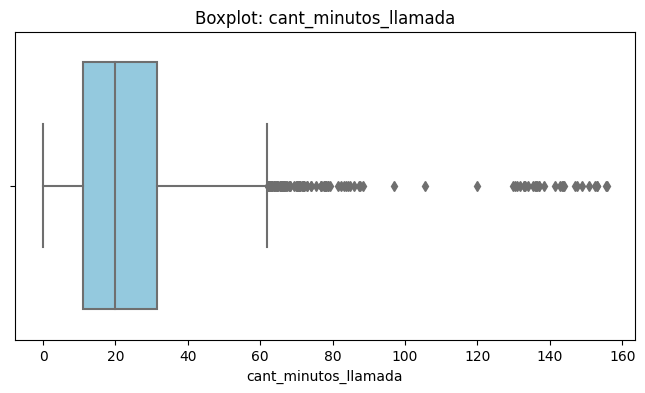

In [81]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

**Insights:**

- **Age:** Presenta un valor atípico negativo cercano a -999. Este valor no corresponde a una edad válida y debe corregirse o tratarse como dato faltante antes de continuar el análisis.
- **cant_mensajes:** Presenta valores atípicos superiores, aproximadamente entre 12 y 17 mensajes. Esto indica que algunos clientes envían más mensajes que la mayoría.
- **cant_llamadas:** Presenta valores atípicos superiores, aproximadamente entre 11 y 15 llamadas. Algunos clientes realizan más llamadas que el comportamiento habitual.
- **cant_minutos_llamada:** Presenta numerosos valores atípicos superiores, algunos cercanos a 155 minutos. Esto indica que existen clientes con un consumo de minutos considerablemente mayor que el resto.

**Conclusión:** Las cuatro variables presentan valores atípicos. Sin embargo, mientras que la edad negativa representa un error de calidad de datos, los valores elevados de mensajes, llamadas y minutos podrían corresponder a comportamientos reales de los clientes. Por lo tanto, no deben eliminarse automáticamente sin una revisión adicional.


In [89]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    print(f'Columna: {col}')
    print(f'Límite superior: {limite_superior}')
    print(f'Valor máximo: {user_profile[col].max()}')
    print()


Columna: cant_mensajes
Límite superior: 11.5
Valor máximo: 17.0

Columna: cant_llamadas
Límite superior: 10.5
Valor máximo: 15.0

Columna: cant_minutos_llamada
Límite superior: 61.8575
Valor máximo: 155.69



In [90]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- **Insights:**

- **cant_mensajes:** Se recomienda mantener los outliers. La mediana es de 5 mensajes, mientras que el valor máximo alcanza 17 y supera el límite IQR de 11.5. Estos valores pueden representar clientes con mayor actividad y no necesariamente errores.

- **cant_llamadas:** Se recomienda mantener los outliers. La mediana es de 4 llamadas y el máximo es de 15, superando el límite de 10.5. Estos registros podrían corresponder a clientes que utilizan el servicio con mayor frecuencia.

- **cant_minutos_llamada:** Se recomienda mantener inicialmente los outliers y revisar los valores más extremos. La mediana es de 19.78 minutos y el máximo alcanza 155.69, muy por encima del límite IQR de 61.86. Aunque el consumo es elevado, podría representar un comportamiento real de algunos usuarios.

**Conclusión:** Las tres variables presentan outliers superiores. Se recomienda conservarlos inicialmente porque podrían aportar información valiosa sobre los patrones de consumo. Antes de eliminarlos, es necesario comprobar que no sean errores de registro.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [91]:
# Crear columna grupo_uso
def clasificar_uso(fila):
    if fila['cant_llamadas'] < 5 and fila['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [92]:
# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [93]:
# Crear columna grupo_edad
def clasificar_edad(fila):
    if fila['age'] < 30:
        return 'Joven'
    elif fila['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [94]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

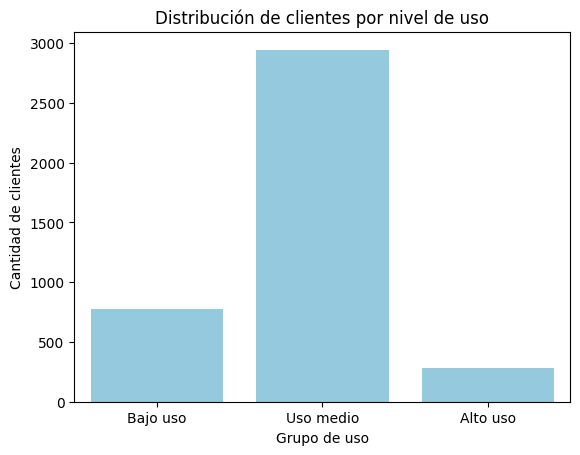

In [95]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    color='skyblue'
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

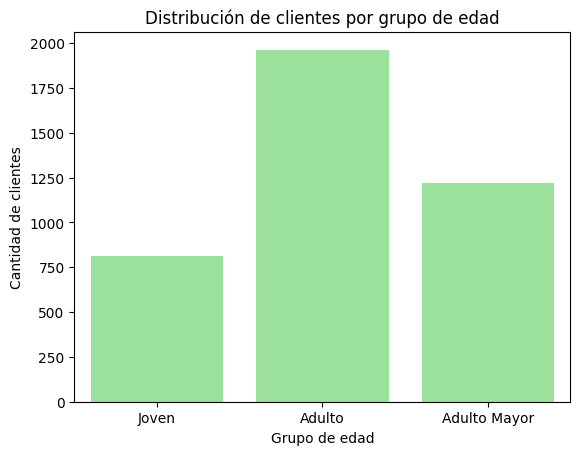

In [96]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    color='lightgreen'
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

# Análisis ejecutivo

### ⚠️ Problemas detectados en los datos

- Se identificó al menos un valor inválido de **-999 en la columna `age`**, que no representa una edad real y requiere limpieza.
- La presencia de valores extremos en las variables de consumo hizo necesario revisar los datos mediante boxplots y el método IQR. Estos valores no deben eliminarse automáticamente, porque podrían representar comportamientos reales de los clientes.

### 🔎 Segmentos por Edad

- El segmento **Adulto (30 a 59 años)** es el más numeroso, con aproximadamente 2.000 clientes.
- Le siguen los **Adultos Mayores (60 años o más)**, con alrededor de 1.300 clientes, y los **Jóvenes (menores de 30 años)**, con aproximadamente 800 clientes.

La empresa tiene una base de clientes concentrada principalmente en personas adultas, aunque también cuenta con una participación importante de adultos mayores.

### 📊 Segmentos por Nivel de Uso

- El grupo de **Uso medio** concentra la mayor cantidad de clientes, aproximadamente 2.900.
- El grupo de **Bajo uso** representa una proporción menor, con alrededor de 800 clientes.
- El segmento de **Alto uso** es el menos numeroso, con aproximadamente 400 clientes.

Esto sugiere que la mayoría de los clientes presenta un consumo moderado de los servicios de telecomunicaciones.

### 📈 Patrones de uso extremo

El análisis mediante boxplots y el método IQR permitió identificar valores atípicos superiores:

- **Mensajes:** límite superior de 11,5 y máximo observado de 17.
- **Llamadas:** límite superior de 10,5 y máximo observado de 15.
- **Minutos de llamada:** límite superior aproximado de 61,86 y máximo observado de 155,69.

Estos valores podrían corresponder a clientes con necesidades de comunicación superiores a las habituales. Se recomienda investigar su comportamiento antes de decidir si deben excluirse del análisis.

### ➡️ Esto sugiere que...

El segmento de uso medio constituye una oportunidad importante por su tamaño. Por otro lado, los clientes de alto uso podrían ser candidatos para planes con mayores beneficios.

Sin embargo, **no es posible afirmar todavía qué segmento genera más ingresos o es más rentable**, porque para ello sería necesario comparar facturación, costos y permanencia de los clientes.

### 💡 Recomendaciones

- **Optimizar los planes actuales** para responder a las necesidades del segmento de uso medio, que concentra la mayor parte de los clientes.
- **Evaluar planes con mayores capacidades** de llamadas y mensajes para clientes de alto uso, verificando primero su rentabilidad.
- **Analizar oportunidades de fidelización** para los clientes de bajo uso, investigando si utilizan poco el servicio por sus necesidades o por limitaciones de la oferta.
- **Corregir los valores inválidos de edad** y revisar los registros extremos antes de realizar análisis adicionales.
- **Cruzar los segmentos de edad y uso con el tipo de plan, la facturación y la cancelación del servicio** para identificar oportunidades comerciales respaldadas por datos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`